**Avant de débuter ce TP** :

1. **Changez le type d'exécution sur Google Colab** : `Exécution > Modifiez le type d'exécution > T4 GPU`
2. **Installez les paquets ci-dessous** :

In [1]:
! pip install aeon lightning torchmetrics torchinfo

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.4/6.4 MB 77.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 66.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 63.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 56.3 MB/s eta 0:00:00


3. Exécutez ce code pour supprimer quelques messages et avertissements éventuellement affichés.

In [2]:
import logging
logging.getLogger("lightning").setLevel(logging.ERROR)
logging.getLogger("lightning.pytorch.utilities.rank_zero").setLevel(logging.WARNING)
logging.getLogger("lightning.pytorch.accelerators.cuda").setLevel(logging.WARNING)
logger = logging.getLogger("lightning")
logger.propagate = False

import warnings
warnings.filterwarnings("ignore", ".*does not have many workers.*")
warnings.filterwarnings("ignore", ".*Missing logger folder.*")
warnings.filterwarnings("ignore", "`isinstance\\(treespec, LeafSpec\\)` is deprecated.*")

# Identification de chiffres arabiques prononcés

Dans ce notebook, vous allez travailler sur le jeu de données [Spoken Arabic Digits](https://timeseriesclassification.com/description.php?Dataset=SpokenArabicDigits).

Ce jeu de données a été construit à partir d'enregistrements de 44 hommes et 44 femmes arabophones âgés de 18 à 40 ans prononçant les dix chiffres arabes.
Voici quelques informations supplémentaires sur les expériences effectuées :

> This data set is taken from the UCI repository. It is derived from sound. Dataset from 8800 (10 digits x 10 repetitions x 88 speakers) time series of 13 Frequency Cepstral Coefficients (MFCCs) had taken from 44 males and 44 females Arabic native speakers between the ages 18 and 40 to represent ten spoken Arabic digit. Each line on the data base represents 13 MFCCs coefficients in the increasing order separated by spaces. This corresponds to one analysis frame. The 13 Mel Frequency Cepstral Coefficients (MFCCs) are computed with the following conditions; Sampling rate: 11025 Hz, 16 bits Window applied: hamming Filter pre-emphasized: 1-0.97Z^(-1).

**L'objectif est de prédire le chiffre prononcé par le sujet à partir des signaux audio enregistrés puis prétraités.**

## Téléchargement des données, visualisation et prétraitement

La cellule ci-dessous permet de télécharger et charger le jeu de données.

In [3]:
from aeon.datasets import load_classification

X, y = load_classification(
    "SpokenArabicDigits", split=None, load_equal_length=True, extract_path="data"
)

Deux variables Python sont définies :

* `X` contient les entrées (c'est-à-dire les signaux) ; il s'agit d'un tableau NumPy de taille `(n_observations, n_canaux, n_points)`.
* `y` contient les sorties (c'est-à-dire les classes) ; il s'agit d'un tableau NumPy de taille `(n_observations,)`.

### Question 1

**(a)** Déterminez les nombres d'observations (`n_observations`), de canaux (`n_canaux`) et de points (`n_points`).

**(b)** Déterminez les valeurs des classes, c'est-à-dire les valeurs uniques du tableau NumPy `y`.

q1A

In [4]:
n_observations, n_canaux, n_points = X.shape

print(n_observations, n_canaux, n_points)

8798 13 65


Q1B

In [5]:
import numpy as np

np.unique(y)

array(['1', '10', '2', '3', '4', '5', '6', '7', '8', '9'], dtype='<U2')

### Question 2

Effectuez les transformations nécessaires sur les variables `X` et `y` pour les mettre aux formats adaptés. On vous rappelle que :

* les entrées doivent être des nombres flottants à 32 bits.
* les classes doivent être des nombres entiers à  64 bits et que les valeurs des classes doivent être les $C$ premiers entiers naturels (en commençant à compter à partir de zéro), où $C$ est le nombre de classes.

Pour ce faire, vous pouvez utiliser la méthode [`numpy.ndarray.astype()`](https://numpy.org/doc/stable/reference/generated/numpy.ndarray.astype.html) ou la fonction [`numpy.astype()`](https://numpy.org/doc/2.0/reference/generated/numpy.astype.html). Les types correspondants sont `numpy.float32` et `numpy.int64` respectivement.

In [7]:
#on convertit les entrées X en nombres à 32 bits
X = X.astype(np.float32)

#on récuppère les classes et on numerotte à partir de 0
y = np.unique(y, return_inverse=True)[1]

#convertion de y en nombres entiers à 64 bits
y = y.astype(np.int64)

#verification
print(X.dtype)
print(y.dtype)
print(np.unique(y))

float32
int64
[0 1 2 3 4 5 6 7 8 9]


La fonction `plot_sample()` définie ci-dessous permet d'afficher une observation.

In [8]:
import matplotlib.pyplot as plt


def plot_sample(X, y, idx):
    """Plot the sample for the given index.

    Parameters
    ----------
    X : array, shape = (n_samples, n_channels, n_points)
        Input samples.

    y : array, shape = (n_samples)
        Target samples.

    idx : int
        Index of the sample to plot.
    """
    if not (isinstance(idx, int) and (0 <= idx < len(X))):
        raise ValueError("L'indice n'est pas valide.")

    for i in range(X.shape[1]):
        plt.plot(X[idx, i])
    _ = plt.title(f"Chiffre {y[idx].item()}")

### Question 3

Appelez la fonction `plot_sample()` pour visualiser quelques observations du jeu de données.

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

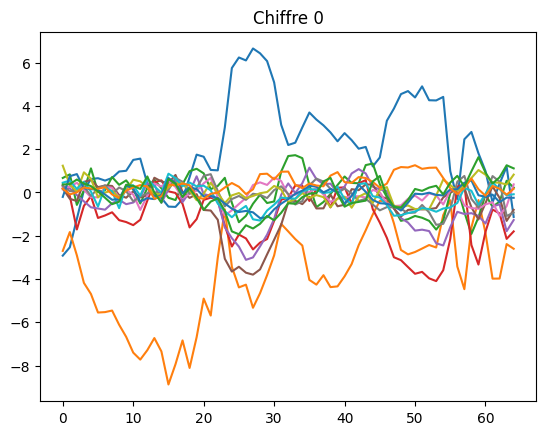

In [11]:
#on veut les observations 0, 100 et 500
for i in [0, 100, 500]:
  plt.figure()
# signaux de l'observation i
plot_sample(X, y, i)
plt.show()

on a quelques valeurs aberrantes de pistes audio (bleu, orange) mais une grosse tendance autour de la prononciation du 0 avec la majorité des courbes autour de ce chiffre.

### Question 4

Calculez la distribution des classes.
Utilisez ces résultats pour proposer une métrique de classification pertinente.
Pour cette métrique, indiquez la valeur (approximative) d'un modèle trivial, par exemple celui prédisant toujours la même classe ou celui prédisant les classes de manière totalement aléatoire (sans utiliser les données en entrée).

In [13]:
#nbr d'observations par classe
classes, counts = np.unique(y, return_counts=True)

print("Classes :", classes)
print("Effectifs :", counts)
print("Proportions :", counts / len(y))

Classes : [0 1 2 3 4 5 6 7 8 9]
Effectifs : [880 878 880 880 880 880 880 880 880 880]
Proportions : [0.10002273 0.09979541 0.10002273 0.10002273 0.10002273 0.10002273
 0.10002273 0.10002273 0.10002273 0.10002273]


**Réponse** : TODO
Les classes sont équilibrées, avec 880 observations pour chacune des 10 classes, (sauf la classe 1 avec 878 d'effectif mais qui reste vraiement proche).
L'exactitude (accuracy), qui correspond à la proportion de prédictions correctes, est donc une métrique pertinente pour la suite.
Un modèle trivial prédisant toujours la même classe aurait une exactitude de 10 %. Un modèle prédisant uniformément les classes au hasard aurait également une exactitude moyenne de 10 %

### Question 5

Séparez le jeu de données en trois jeux de données :

* le jeu d'entraînement avec 6000 observations,
* le jeu de validation avec 1000 observations, et
* le jeu d'évaluation avec le reste.

Pour ce faire, vous pouvez utiliser la fonction [`sklearn.model_selection.train_test_split()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html). Les trois jeux de données doivent conserver (approximativement) la distribution des classes, vous utiliserez l'argument `stratify` pour respecter cette propriété.

In [21]:

from sklearn.model_selection import train_test_split

#split train du reste des données
X_train, X_temp, y_train, y_temp = train_test_split(
X, y, train_size=6000, stratify=y, random_state=42
)

#split validition et test
X_val, X_test, y_val, y_test = train_test_split(
X_temp, y_temp, train_size=1000, stratify=y_temp, random_state=42
)

#veirifiaction taille des trois jeux de données
print("Entraînement :", len(y_train))
print("Validation :", len(y_val))
print("Test :", len(y_test))

Entraînement : 6000
Validation : 1000
Test : 1798


ici on a donc bien les 6000 en train, 1000 pour valider et 1798 en test ; ce qui s'explique par le fait que la classe 2 ne compte que 878 au lieu de 880 obeservations, ce qui se répercute ici par construction.

### Question 6

L'approche utilisée à la question précédente a un inconvénient méthodologique. Identifiez lequel. La réponse se trouve dans la description du jeu de données, au début de ce notebook.

> **Remarque** : Ne passez pas trop de temps sur cette question, ce n'est pas très grave si vous n'avez pas la réponse. Vous pourrez également y réfléchir pendant l'entraînement des modèles.

**Réponse** : TODO
Le jeu de données contient plusieurs enregistrements provenant des mêmes 88 individus (un enregistrement par chiffre par personne, donc 10 enregistrements par individu). Avec une séparation aléatoire des observations, les enregistrements d'un même individu (pour chaque chiffre différent) peuvent se retrouver à la fois dans les jeux d'entraînement, de validation et de test.
Le modèle risque donc d'apprendre des caractéristiques propres à la voix des individus, ce qui peut surestimer ses performances sur de nouveaux locuteurs.
Il serait préférable d'effectuer une séparation par individu, afin que les personnes présentes dans le jeu de test soient différentes de celles du jeu d'entraînement.

### Question 7

Convertissez vos 6 tableaux NumPy (les entrées et les sorties pour les trois jeux de données) en tenseurs PyTorch. La fonction à utiliser est [`torch.from_numpy()`](https://docs.pytorch.org/docs/2.14/generated/torch.from_numpy.html).

In [22]:
import torch

#pour train data
X_train = torch.from_numpy(X_train)
y_train = torch.from_numpy(y_train)

#pour validation
X_val = torch.from_numpy(X_val)
y_val = torch.from_numpy(y_val)

#pour test
X_test = torch.from_numpy(X_test)
y_test = torch.from_numpy(y_test)

print(type(X_train))
print(X_train.shape)
print(X_train.dtype)
print(y_train.dtype)

<class 'torch.Tensor'>
torch.Size([6000, 13, 65])
torch.float32
torch.int64


remarque : ne lancer le chunk q7 que une fois sinon ça ne marche pas plusieurs fois
c'est du au fait que c'est déjà converti en tensor Pytorch

### Question 8

Créez les *dataloaders* pour les jeux d'entraînement et de validation en utilisant la classe [`torch.utils.data.DataLoader()`](https://docs.pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader) avec des lots de taille $32$. N'oubliez pas de mélanger (*shuffle*) les observations pour le jeu d'entraînement, mais pas pour le jeu de validation. Pour créer les jeux de données, vous pouvez utiliser la classe [`torch.utils.data.TensorDataset()`](https://docs.pytorch.org/docs/stable/data.html#torch.utils.data.TensorDataset).

In [ ]:
# TODO

## Classe de base pour la classification

Vous allez entraîner plusieurs modèles avec des architectures différentes.
Néanmoins, plusieurs opérations seront identiques pour tous ces modèles.
C'est pourquoi nous allons tout d'abord définir une classe de base avec toutes les opérations identiques.
La classe `BaseClass()` définie ci-dessous va contenir ces opérations communes.

### Question 9

Complétez le code manquant dans les méthodes `__init__()`, `step()` et `configure_optimizers()` de la classe `BaseClass()` avec les informations suivantes :
* `__init__()` : il faut définir la fonction de perte (`self.loss`) et les métriques pour les jeux d'entraînement (`self.metric_train`) et d'évaluation (`self.metric_val`);
* `step()` : étant donné un lot d'observations (`batch`), il faut :
    + récupérer les entrées (`X`) et les labels (`y`),
    + calculer les logits pour ces entrées (`logits`),
    + calculer la fonction de coût entre les logits et les labels (`loss`),
    + calculer la classe prédite pour chacune des observations du lot (`y_pred`).
* `configure_optimizers()` : on utilisera l'algorithme d'optimisation [`torch.optim.Adam()`](https://pytorch.org/docs/stable/generated/torch.optim.Adam.html) avec un taux d'apprentissage (*learning rate*) de $10^{-4}$.

In [ ]:
import lightning as L


class BaseClass(L.LightningModule):

    def __init__(self):
        """Constructeur.

        Dans le constructeur, on exécute le constructeur de la clase mère et on définit
        toutes les couches et fonctions d'activation de notre réseau de neurones.
        """
        super().__init__()  # Toujours exécuter le constructeur de la classe mère

        ### BEGIN TODO ###
        # Initialisation de la fonction de perte
        # self.loss =

        # Initialisation des métriques
        # self.metric_train =
        # self.metric_val =
        #### END TODO ####

    def step(self, batch, dataset):
        """Effectue une étape.

        Une étape consiste à passer d'un lot d'observations (l'argument batch)
        à l'évaluation de la fonction de coût pour ce lot d'observations.

        Parameters
        ----------
        batch : tuple
            Un lot d'observations. Le premier élément du tuple est le lot
            des entrées, le second est le lot des labels.

        dataset : {"training", "validation"}
            Jeu de données utilisé.

        Returns
        -------
        loss : Tensor, shape = (1,)
            La fonction de coût pour ce lot d'observations.
        """
        ### BEGIN TODO ###
        # X, y =   # X correspond aux signaux, y aux classes
        # logits =   # Passe avant, qui renvoie les logits
        # loss =   # Évaluation de la fonction de perte
        # y_pred =   # Prédictions du modèle
        #### END TODO ###

        if dataset == "training":
            metric = self.metric_train
            name = "train"
            bar_step = True
        else:
            metric = self.metric_val
            name = "val"
            bar_step = False

        metric_score = metric(y_pred, y) # Évaluation de la métrique
        self.log(f"loss_{name}", loss, prog_bar=bar_step, on_step=bar_step, on_epoch=True)
        self.log(f"metric_{name}", metric_score, prog_bar=bar_step, on_step=bar_step, on_epoch=True)

        return loss

    def training_step(self, batch):
        """Effectue une étape d'entraînement."""
        return self.step(batch, "training")

    def validation_step(self, batch):
        """Effectue une étape de validation."""
        return self.step(batch, "validation")

    def on_train_start(self):
        """Code exécuté au début de l'entraînement."""
        string = f"Version {self.trainer.logger.version}"
        print(f"{string}\n{'=' * len(string)}\n")

    def on_train_epoch_end(self):
        """Code exécuté à la fin de chaque époque d'entraînement."""
        metrics = self.trainer.callback_metrics
        string = (f"""
            Époque {self.trainer.current_epoch + 1} / {self.trainer.max_epochs}
            -------------------------------------------------
            |     Jeu      | Fonction de perte | Exactitude |
            | ------------ | ----------------- | ---------- |
            | Entraînement |{metrics['loss_train'].item():^19.5f}|{metrics['metric_train'].item():^12.3%}|
            |  Validation  |{metrics['loss_val'].item():^19.5f}|{metrics['metric_val'].item():^12.3%}|
            -------------------------------------------------
        """)
        string = '\n'.join([line.strip() for line in string.strip().split('\n')])
        print(string, '\n')

    def configure_optimizers(self):
        """Configure l'algorithme d'optimisation à utiliser."""
        ### BEGIN TODO ###
        # optimizer =
        #### END TODO ####
        return optimizer

## Classification par perceptron multicouche

Comme la longueur de chacun des signaux est fixe après prétraitement des données, il est possible d'utiliser un perceptron multicouche.

Vous allez implémenter un perceptron multicouche dans la classe `MLP()` définie ci-dessous avec l'architecture séquentielle suivante :

* Aplatissement de l'observation pour la transformer en un tenseur à une dimension (un vecteur)
* Couche linéaire avec 256 variables en sortie
* Fonction d'action ReLU
* Couche de désaction (*dropout*) avec une probabilité de $0.2$
* Couche linéaire avec 64 variables en sortie
* Fonction d'action ReLU
* Couche linéaire avec 10 variables en sortie

Voici les liens vers les documentations des classes pertinentes :
[`torch.nn.Flatten()`](https://pytorch.org/docs/stable/generated/torch.nn.Flatten.html),
[`torch.nn.Linear()`](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html),
[`torch.nn.ReLU()`](https://pytorch.org/docs/stable/generated/torch.nn.ReLU.html) et
[`torch.nn.Dropout()`](https://pytorch.org/docs/stable/generated/torch.nn.Dropout.html).

### Question 10

Complétez le code manquant dans les méthodes `__init__()` et `forward()` de la classe `MLP()`.
Affichez un résumé de l'architecture. Combien de paramètres entraînables a-t-elle ?

In [ ]:
class MLP(BaseClass):

    def __init__(self):
        super().__init__()

        ### BEGIN TODO ###

        #### END TODO ####

    def forward(self, x):
        ### BEGIN TODO ###
        # logits =
        #### END TODO ####
        return logits

In [ ]:
# TODO

### Question 11

Entraînez votre modèle pendant $10$ époques.

In [ ]:
# TODO

## Classification par réseau de neurones convolutif

Comme la longueur de chacun des signaux est fixe après prétraitement des données et que les données sont séquentielles, il est également possible et pertinent d'utiliser un réseau de neurones convolutif.

Vous allez implémenter un réseau de neurones convolutif dans la classe `CNN()` définie ci-dessous avec l'architecture séquentielle suivante :

* Couche de convolution unidimensionnelle avec $32$ canaux en sortie et un noyau de taille $7$
* Fonction d'action ReLU
* Couche de regroupement unidimensionnelle avec un noyau et un pas de taille $2$
* Couche de convolution unidimensionnelle avec $64$ canaux en sortie et un noyau de taille $5$
* Fonction d'action ReLU
* Couche de regroupement unidimensionnelle avec un noyau et un pas de taille $2$
* Couche de convolution unidimensionnelle avec $128$ canaux en sortie et un noyau de taille $3$
* Fonction d'action ReLU
* Couche de regroupement unidimensionnelle avec un noyau et un pas de taille $2$
* Aplatissement de l'entrée (en deux dimensions) pour la transformer en un tenseur à une dimension (un vecteur)
* Couche linéaire avec $640$ variables en entrée et $256$ variables en sortie
* Fonction d'action ReLU
* Couche linéaire avec $10$ variables en sortie

Voici les liens vers les documentations des classes pertinentes :
[`torch.nn.Conv1d()`](https://pytorch.org/docs/stable/generated/torch.nn.Conv1d.html),
[`torch.nn.ReLU()`](https://pytorch.org/docs/stable/generated/torch.nn.ReLU.html),
[`torch.nn.MaxPool1d()`](https://pytorch.org/docs/stable/generated/torch.nn.MaxPool1d.html),
[`torch.nn.Flatten()`](https://pytorch.org/docs/stable/generated/torch.nn.Flatten.html) et
[`torch.nn.Linear()`](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html).

### Question 12

Complétez le code manquant dans les méthodes `__init__()` et `forward()` de la classe `CNN()`.
Affichez un résumé de l'architecture. Combien de paramètres entraînables a-t-elle ?

In [ ]:
class CNN(BaseClass):

    def __init__(self):
        super().__init__()

        ### BEGIN TODO ###

        #### END TODO ####

    def forward(self, x):
        ### BEGIN TODO ###
        # logits =
        #### END TODO ####
        return logits

In [ ]:
# TODO

### Question 13

Entraînez votre modèle pendant $10$ époques.

In [ ]:
# TODO

## Classification par réseau de neurones récurrent

Comme les données sont séquentielles, il est également possible et pertinent d'utiliser un réseau de neurones récurrent.

Vous allez implémenter un réseau de neurones récurrent dans la classe `RNN()` définie ci-dessous avec l'architecture séquentielle suivante :

* Couche récurrente de type LSTM (unidirectionnelle) avec $256$ variables pour chaque état caché
* Couche linéaire avec 10 variables en sortie

Voici les liens vers les documentations des classes pertinentes :
[`torch.nn.LSTM()`](https://pytorch.org/docs/stable/generated/torch.nn.LSTM.html) et
[`torch.nn.Linear()`](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html).
Lisez attentativement la documentation de la classe [`torch.nn.LSTM()`](https://pytorch.org/docs/stable/generated/torch.nn.LSTM.html), notamment concernant les formes attendues des tenseurs en entrée et en sortie.
Vous pouvez utiliser la fonction [`torch.transpose()`](https://docs.pytorch.org/docs/2.14/generated/torch.transpose.html) pour modifier l'ordre des dimensions d'un tenseur.

### Question 14

Complétez le code manquant dans les méthodes `__init__()` et `forward()` de la classe `RNN()`.
Affichez un résumé de l'architecture. Combien de paramètres entraînables a-t-elle ?

In [ ]:
class RNN(BaseClass):

    def __init__(self):
        super().__init__()

        ### BEGIN TODO ###

        #### END TODO ####

    def forward(self, x):
        ### BEGIN TODO ###
        # logits =
        #### END TODO ####
        return logits

In [ ]:
# TODO

### Question 15

Entraînez votre modèle pendant $10$ époques.

In [ ]:
# TODO

### Question 16

Finalement, lequel de vos trois modèles est le meilleur ? Justifiez votre réponse.

**Réponse** : TODO